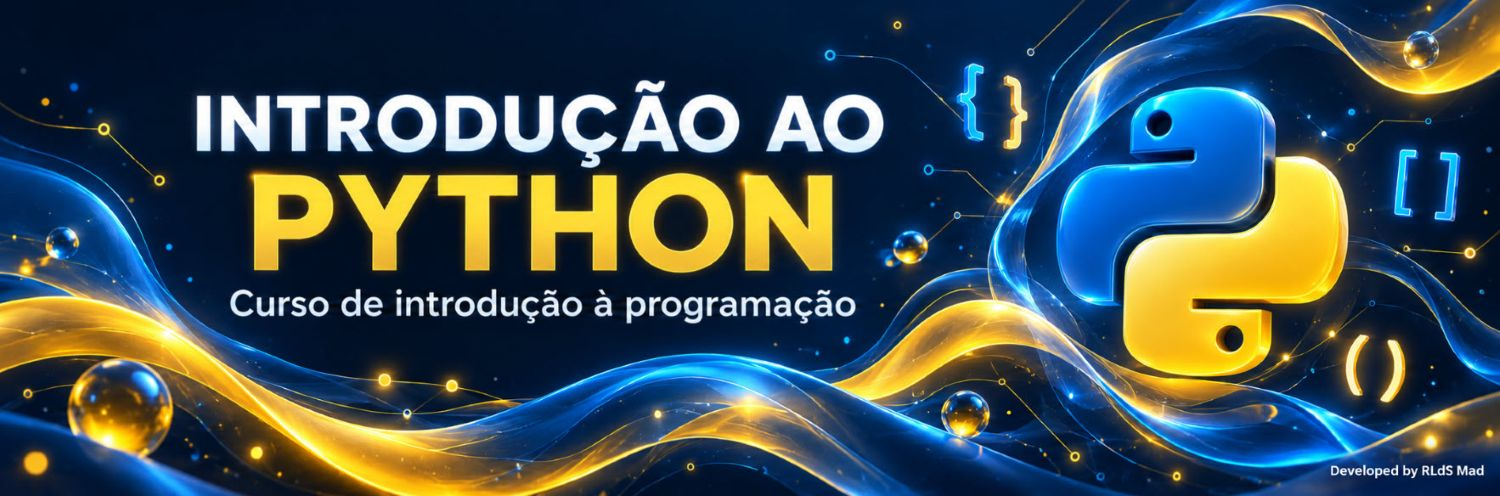

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_2_avancado/RLdS_N2_03_ScikitLearn_Fundamentos.ipynb)


# Nível avançado · Módulo 3 – Scikit-learn: fundamentos e regressão
## Do primeiro estimador à avaliação em dados novos

Este é o módulo de fundamentos e regressão com o scikit-learn.

**Pré-requisitos:** funções Python, arrays NumPy, DataFrames Pandas, seleção de linhas e colunas, médias e noção da equação de uma reta. 

**Duração sugerida:** 8–12 horas, com exercícios.

**Objetivos:** distinguir ajuste de avaliação; utilizar a API do scikit-learn; interpretar métricas de regressão; comparar com uma previsão de referência; trabalhar com várias variáveis; reconhecer sobreajuste; combinar preparação e modelo numa pipeline; escolher configurações com validação cruzada sem consultar o teste.

### Como utilizar
Executa de cima para baixo com Shift + Enter em Jupyter, VS Code ou Colab. Os exercícios têm espaços facultativos de resposta; as soluções finais não dependem de os preencheres. As figuras estão incorporadas no notebook e não dependem de imagens externas. Depois de instalar as dependências, o percurso funciona sem Internet.

As exportações criam ou substituem ficheiros de demonstração em `sklearn01_lab`, no diretório de trabalho. No Colab, descarrega os resultados antes de terminar a sessão. Reinicia o kernel e executa tudo para verificar a reprodução.

### Índice
1. Ambiente, vocabulário e API
2. Regressão linear simples e interpretação
3. Cenário principal e separação de dados
4. Métricas: MAE, MSE, RMSE e R²
5. Pré-processamento e primeira pipeline
6. Regressão múltipla e coeficientes
7. Validação cruzada e análise de resíduos
8. Subajuste, sobreajuste e regressão polinomial
9. Regularização: Ridge e introdução ao Lasso
10. Seleção no treino e avaliação final no teste
11. Miniprojeto, previsões e exportação
12. Exercícios resolvidos e consulta rápida

**Regra central:** as escolhas são feitas no conjunto de desenvolvimento. O teste reservado só é utilizado para a avaliação final e não volta a orientar escolhas.

## Introdução ao scikit-learn

O **scikit-learn** é uma `biblioteca de código aberto de Python` dedicada à aprendizagem automática (machine learning). Disponibiliza ferramentas para construir modelos que aprendem padrões a partir de dados e utilizam esses padrões para produzir previsões ou identificar estruturas.


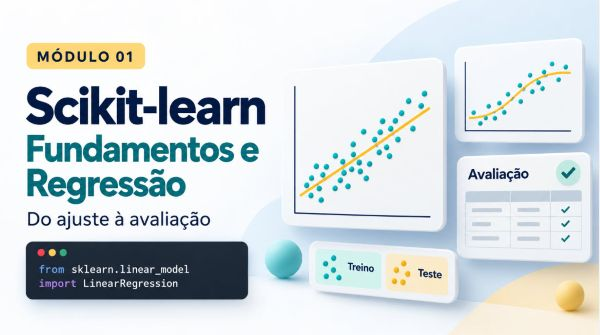

## 1. Preparar o ambiente
O pacote chama-se **scikit-learn** na instalação e é importado como **sklearn**. Descomenta a instalação apenas se necessário e reinicia o kernel depois. Os exemplos usam `root_mean_squared_error`, disponível em scikit-learn 1.4+.

Não é preciso instalar o pacote chamado `sklearn`: instala `scikit-learn`.

In [1]:
# O Colab já inclui estas bibliotecas. Noutros ambientes, descomenta a linha seguinte se faltar alguma.
# %pip install "scikit-learn>=1.4" numpy pandas matplotlib

In [2]:
from pathlib import Path
from io import BytesIO
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.exceptions import NotFittedError

PASTA = Path.cwd() / "sklearn01_lab"
PASTA.mkdir(exist_ok=True)
VERSOES = {p: version(p) for p in ["scikit-learn", "numpy", "pandas", "matplotlib"]}
VERSOES["python"] = platform.python_version()
display(pd.Series(VERSOES, name="versao"))

def mostrar_figura(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

scikit-learn     1.9.1
numpy            2.5.4
pandas           3.0.6
matplotlib      3.11.2
python          3.12.3
Name: versao, dtype: str

### 1.1 Vocabulário antes do código
| Termo | Significado | Exemplo |
|---|---|---|
| Observação/amostra | Uma linha de dados | Uma habitação fictícia |
| Variável de entrada/feature | Informação disponível ao prever | Área e ocupantes |
| Alvo/target | Valor que queremos prever | Consumo mensal em kWh |
| Regressão | Prever um valor numérico | Quantidade de energia |
| Classificação | Prever uma categoria | Tipo de ocorrência; tema do módulo 4 |
| Parâmetro aprendido | Valor estimado durante o ajuste | Coeficiente da área |
| Hiperparâmetro | Configuração escolhida antes do ajuste | Intensidade de regularização `alpha` |
| Generalização | Desempenho em dados novos comparáveis | Prever outra habitação |

Uma associação aprendida não prova causalidade. Uma previsão numérica não explica, por si só, por que o resultado ocorreu.

### 1.2 O padrão da API
| Método/atributo | Utilização |
|---|---|
| `fit(X, y)` | Aprender a partir de dados de treino |
| `predict(X_novo)` | Produzir previsões com um modelo ajustado |
| `fit(X)` num transformador | Aprender estatísticas de transformação |
| `transform(X)` | Aplicar uma transformação já aprendida |
| `fit_transform(X)` | Ajustar e transformar os dados de ajuste |
| `get_params()` / `set_params(...)` | Consultar/alterar configurações |
| `coef_`, `intercept_` | Atributos aprendidos de modelos lineares |

A notação `X` representa habitualmente uma matriz `(n_observacoes, n_variaveis)` e `y` um vetor `(n_observacoes,)` para um único alvo. Uma única previsão com três variáveis precisa de forma `(1,3)`.

Nem todos os estimadores têm todos os métodos: uma `LinearRegression` prevê, enquanto um `StandardScaler` transforma.

### 1.3 Criar um estimador não é ajustá-lo

O objeto recém-criado conhece a configuração, mas ainda não aprendeu coeficientes. Uma previsão antes de `fit` é uma falha esperada.

In [3]:
modelo_nao_ajustado = LinearRegression()
print("Configuração fit_intercept:", modelo_nao_ajustado.get_params()["fit_intercept"])
try:
    modelo_nao_ajustado.predict([[2.]])
except NotFittedError:
    print("Falha esperada: é necessário ajustar antes de prever.")

Configuração fit_intercept: True
Falha esperada: é necessário ajustar antes de prever.


### Exercício 1

Explica a diferença entre parâmetro e hiperparâmetro. Cria uma `LinearRegression(fit_intercept=False)` e confirma a configuração com `get_params()`, sem a ajustar.

Tenta resolver antes de consultar a solução no final.

In [4]:
# Exercício 1 – escreve a tua resolução aqui.


## 2. Regressão linear simples: uma ponte matemática
Uma reta pode escrever-se como:

$$\widehat{y}=\beta_0+\beta_1x.$$

O ajuste por mínimos quadrados escolhe coeficientes para minimizar a soma dos quadrados dos resíduos $y_i-\widehat{y}_i$. Para uma variável não constante:

$$\beta_1=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sum_i(x_i-\bar{x})^2},\qquad
\beta_0=\bar{y}-\beta_1\bar{x}.$$

O exemplo seguinte usa **uma pequena experiência sintética de deslocação**, só para compreender a reta. Não utilizaremos o seu erro de ajuste como estimativa de desempenho em dados novos.

In [5]:
# Distância em km e duração em minutos; exemplo fictício, independente do projeto principal.
distancia_km = np.array([1., 3., 4., 6., 8., 9.])
duracao_min = np.array([6., 9., 13., 15., 21., 22.])
X_reta = distancia_km.reshape(-1, 1)
xc = distancia_km - distancia_km.mean()
yc = duracao_min - duracao_min.mean()
declive_manual = np.sum(xc * yc) / np.sum(xc ** 2)
intercecao_manual = duracao_min.mean() - declive_manual * distancia_km.mean()
reta = LinearRegression().fit(X_reta, duracao_min)
print("Formas X e y:", X_reta.shape, duracao_min.shape)
print("Declive manual / sklearn:", declive_manual, reta.coef_[0])
print("Interceção manual / sklearn:", intercecao_manual, reta.intercept_)
np.testing.assert_allclose([declive_manual, intercecao_manual], [reta.coef_[0], reta.intercept_], atol=1e-12)
print("Previsão para 5 km:", reta.predict(np.array([[5.]])))

Formas X e y: (6, 1) (6,)
Declive manual / sklearn: 2.0640569395017794 2.064056939501779
Interceção manual / sklearn: 3.6690391459074725 3.669039145907476
Previsão para 5 km: [13.98932384]


### 2.1 Coeficientes e extrapolação

O declive tem unidades de minutos por km; a interceção tem unidades de minutos. Prever dentro do intervalo observado é interpolação; prever fora dele é extrapolação e exige maior cautela.

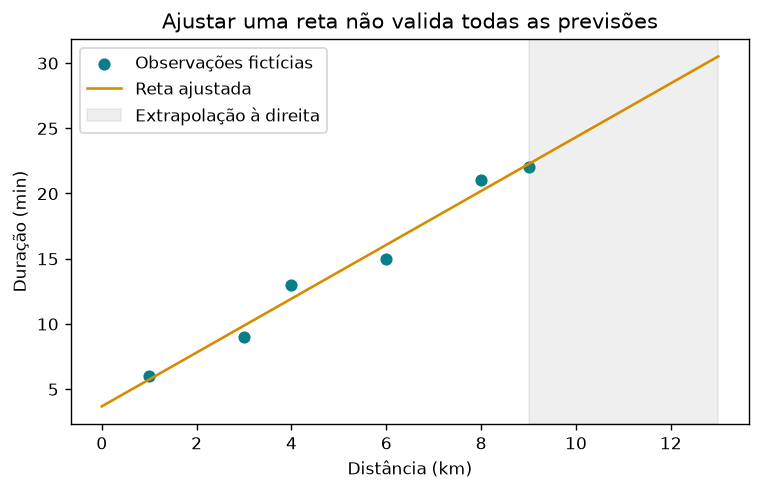

Previsão para 12 km: 28.437722419928825


In [6]:
x_grafico = np.linspace(0, 13, 200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(distancia_km, duracao_min, color="#087e8b", label="Observações fictícias")
ax.plot(x_grafico[:, 0], reta.predict(x_grafico), color="#d58c00", label="Reta ajustada")
ax.axvspan(9, 13, color="grey", alpha=0.12, label="Extrapolação à direita")
ax.set(xlabel="Distância (km)", ylabel="Duração (min)", title="Ajustar uma reta não valida todas as previsões")
ax.legend(); mostrar_figura(fig)
print("Previsão para 12 km:", reta.predict([[12.]])[0])

**Interpretação:** A interceção em zero pode não ter interpretação física se zero estiver fora do domínio observado. A reta não fornece automaticamente intervalos de previsão. Um coeficiente não prova o efeito de uma intervenção causal.

### Exercício 2

Usando a experiência de deslocação, prevê durações para 2 e 11 km. Mostra a forma de `X_novo` e identifica qual das previsões é uma extrapolação. Não interpretes a previsão como uma garantia.

Tenta resolver antes de consultar a solução no final.

In [7]:
# Exercício 2 – escreve a tua resolução aqui.

## 3. Cenário principal: consumo mensal de energia
**Pergunta:** podemos estimar o consumo mensal de uma habitação a partir da área, do número de ocupantes e da temperatura média exterior?

**Unidade de observação:** uma habitação fictícia num cenário mensal. As linhas são independentes e não representam meses repetidos da mesma habitação. Por isso usamos uma separação aleatória. Num problema temporal ou com várias linhas da mesma pessoa/habitação, a separação teria de respeitar essa estrutura.

| Coluna | Significado | Papel |
|---|---|---|
| id_habitacao | Identificador fictício | Identificação, excluída de X |
| area_m2 | Área | Entrada disponível na previsão |
| ocupantes | Número de ocupantes | Entrada disponível na previsão |
| temperatura_C | Temperatura média assumida conhecida para este exercício | Entrada com algumas ausências |
| consumo_kwh | Consumo observado sintético | Alvo |

Se a temperatura real do mês só for conhecida no fim do mês, não pode ser usada numa previsão feita no início. Nesse caso seria necessário usar uma previsão meteorológica ou alterar o momento da previsão. Aqui assumimos explicitamente que o cenário de temperatura é conhecido.

Os dados não descrevem consumos reais e o mecanismo linear foi escolhido para fins pedagógicos.

In [8]:
rng = np.random.default_rng(724)
n = 360
area = rng.uniform(40, 180, n)
ocupantes = rng.integers(1, 6, n)
temperatura = rng.uniform(5, 25, n)
consumo = 160 + 1.5 * area + 18 * ocupantes - 6 * temperatura + rng.normal(0, 18, n)
dados = pd.DataFrame({
    "id_habitacao": [f"H{i:04d}" for i in range(n)],
    "area_m2": area, "ocupantes": ocupantes, "temperatura_C": temperatura,
    "consumo_kwh": consumo
})
# O valor existe no processo sintético, mas algumas entradas observadas estão em falta.
dados.loc[rng.choice(n, 16, replace=False), "temperatura_C"] = np.nan
FEATURES = ["area_m2", "ocupantes", "temperatura_C"]
X = dados[FEATURES].copy()
y = dados["consumo_kwh"].copy()
assert dados["id_habitacao"].is_unique and y.notna().all()
assert "consumo_kwh" not in X.columns and "id_habitacao" not in X.columns
print("Formas:", X.shape, y.shape)

Formas: (360, 3) (360,)


### 3.1 Separar antes de explorar e preparar
Reservamos 20% para teste. As explorações e escolhas seguintes usam apenas as restantes 80%, chamadas **conjunto de desenvolvimento** (`X_dev`, `y_dev`). Dentro deste conjunto, a validação cruzada vai criar subconjuntos de treino e validação.

Uma terceira partição fixa de validação seria outra opção. Aqui usamos desenvolvimento + teste e validação cruzada dentro do desenvolvimento, sem uma partição fixa adicional.

`random_state` fixa a separação para reprodução; não torna a amostra representativa por si só. Não repetimos sementes até obter um teste favorável.

In [9]:
X_dev, X_teste, y_dev, y_teste = train_test_split(X, y, test_size=0.20, random_state=42)
assert set(X_dev.index).isdisjoint(X_teste.index)
assert len(X_dev) + len(X_teste) == len(X)
assert X_dev.index.equals(y_dev.index) and X_teste.index.equals(y_teste.index)
print("Desenvolvimento:", X_dev.shape, "| teste reservado:", X_teste.shape)
# A partir daqui não inspecionamos os alvos do teste até à avaliação final.
display(X_dev.head())
display(X_dev.describe())
display(X_dev.isna().sum())

Desenvolvimento: (288, 3) | teste reservado: (72, 3)


,area_m2,ocupantes,temperatura_C
289,68.976337,3,17.177876
336,67.848808,5,5.733163
231,169.729005,4,21.845371
75,51.263912,2,24.509365
194,152.907616,3,5.815807


,area_m2,ocupantes,temperatura_C
count,288.000000,288.000000,275.000000
mean,109.499381,2.947917,14.944927
std,41.349691,1.426746,5.874426
min,41.434676,1.000000,5.047731
25%,73.909976,2.000000,9.892191
50%,112.849708,3.000000,15.460690
75%,146.821480,4.000000,19.901704
max,179.759460,5.000000,24.982740


area_m2           0
ocupantes         0
temperatura_C    13
dtype: int64

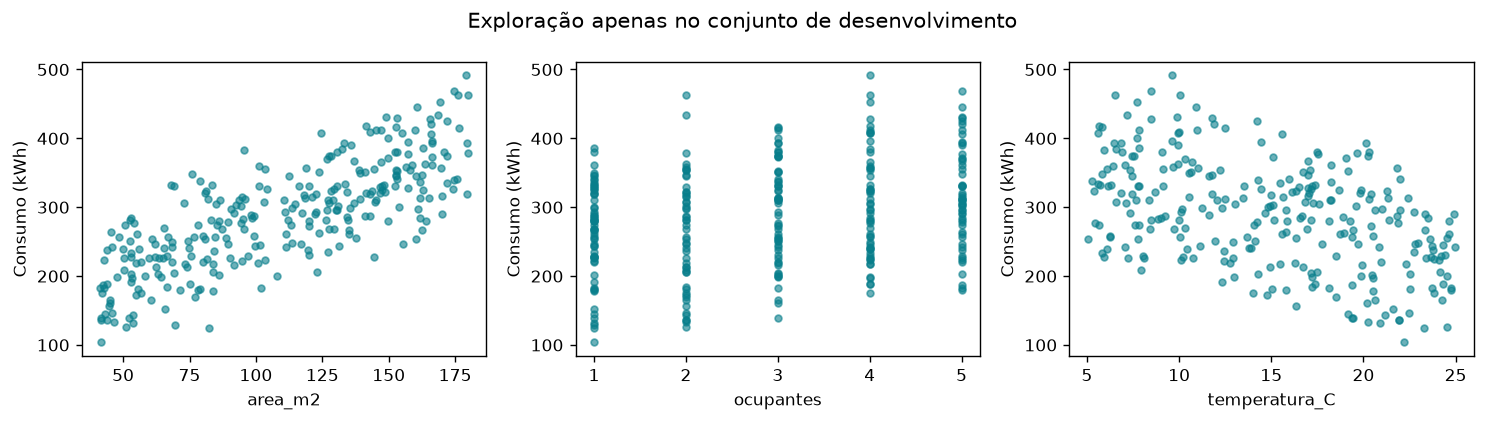

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, coluna in zip(eixos, FEATURES):
    ax.scatter(X_dev[coluna], y_dev, s=15, alpha=0.6, color="#087e8b")
    ax.set(xlabel=coluna, ylabel="Consumo (kWh)")
fig.suptitle("Exploração apenas no conjunto de desenvolvimento")
fig.tight_layout(); mostrar_figura(fig)

### Exercício 3

Cria uma separação reprodutível de um conjunto sintético independente com 100 linhas e duas entradas, reservando 25% para teste. Verifica as formas e a ausência de interseção de índices. Não alteres a separação principal.

Tenta resolver antes de consultar a solução no final.

In [11]:
# Exercício 3 – escreve a tua resolução aqui.


## 4. Métricas: que pergunta responde cada uma?
Se $e_i=y_i-\widehat{y}_i$:

$$\mathrm{MAE}=\frac1n\sum_i|e_i|,\qquad
\mathrm{MSE}=\frac1n\sum_i e_i^2,\qquad
\mathrm{RMSE}=\sqrt{\mathrm{MSE}}.$$

$$R^2=1-\frac{\sum_i(y_i-\widehat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

| Métrica | Unidades | Leitura |
|---|---|---|
| MAE | kWh | Erro absoluto médio |
| MSE | kWh² | Penaliza quadraticamente erros grandes |
| RMSE | kWh | Raiz do MSE; sensível a erros grandes |
| R² | Sem unidade | Comparação com a previsão constante da média dos alvos avaliados |

MAE/MSE/RMSE menores são melhores. R² maior é melhor: 1 é previsão perfeita; 0 corresponde ao erro quadrático da média do conjunto avaliado; pode ser negativo. **R² não é uma percentagem de previsões corretas.** Com alvo constante ou menos de duas observações, a interpretação de R² exige cuidados adicionais.

Uma métrica só é útil em relação a uma referência, às unidades e ao custo dos erros. Um RMSE de 20 kWh não é automaticamente aceitável para qualquer aplicação.

In [12]:
def avaliar_regressao(y_real, y_previsto):
    return {"MAE_kwh": mean_absolute_error(y_real, y_previsto),
            "MSE_kwh2": mean_squared_error(y_real, y_previsto),
            "RMSE_kwh": root_mean_squared_error(y_real, y_previsto),
            "R2": r2_score(y_real, y_previsto)}

exemplo_y = np.array([10., 20., 30., 40.])
exemplo_prev = np.array([12., 18., 33., 37.])
display(pd.Series(avaliar_regressao(exemplo_y, exemplo_prev)))
print("R² de uma previsão muito má:", r2_score(exemplo_y, np.zeros(4)))
assert np.isclose(root_mean_squared_error(exemplo_y, exemplo_prev)**2,
                   mean_squared_error(exemplo_y, exemplo_prev))

MAE_kwh     2.50000
MSE_kwh2    6.50000
RMSE_kwh    2.54951
R2          0.94800
dtype: float64

R² de uma previsão muito má: -5.0


### 4.1 Primeira referência e primeira reta no desenvolvimento

Uma referência simples, como prever sempre a média aprendida no treino, ajuda a quantificar o valor acrescentado. Estes resultados abaixo são **erros de ajuste no desenvolvimento**, ainda não estimativas independentes de generalização.

In [13]:
base_dev = DummyRegressor(strategy="mean").fit(X_dev, y_dev)
linear_simples = LinearRegression().fit(X_dev[["area_m2"]], y_dev)
tabela_ajuste = pd.DataFrame({
    "referencia_media": avaliar_regressao(y_dev, base_dev.predict(X_dev)),
    "reta_apenas_area": avaliar_regressao(y_dev, linear_simples.predict(X_dev[["area_m2"]]))
}).T
display(tabela_ajuste)
print("Declive da área:", linear_simples.coef_[0], "kWh por m²")

,MAE_kwh,MSE_kwh2,RMSE_kwh,R2
referencia_media,62.232089,5870.435113,76.618765,0.000000
reta_apenas_area,39.199266,2337.770007,48.350491,0.601772


Declive da área: 1.4399063864196937 kWh por m²


**Interpretação:** O R² da referência da média ajustada e avaliada no mesmo conjunto é zero, salvo casos degenerados. Na validação ou no teste pode ser negativo, porque a média aprendida no treino pode diferir da média dos alvos avaliados.

### Exercício 4

Calcula MAE, MSE e RMSE de `[5., 10., 15.]` e previsões `[4., 12., 14.]`. Confirma manualmente MAE = 4/3 e MSE = 2. Explica as unidades.

Tenta resolver antes de consultar a solução no final.

In [14]:
# Exercício 4 – escreve a tua resolução aqui.


## 5. Pré-processamento: ajustar no treino, aplicar nos restantes
A temperatura contém ausências. Não vamos preencher com zero nem com uma média calculada antes de separar os dados. `SimpleImputer` aprende a mediana no treino. `StandardScaler` aprende médias e desvios para transformar as variáveis.

**Sequência correta num fold:** `fit_transform` no treino do fold → `transform` na validação do fold → avaliar. Nunca ajustamos os transformadores na validação ou no teste.

Uma regressão linear sem regularização não exige necessariamente padronização para fazer previsões equivalentes. A escala é particularmente importante quando penalizamos coeficientes, como no Ridge e no Lasso.

### 5.1 Observar um transformador

Este exemplo ajusta o transformador apenas no desenvolvimento. Na validação cruzada usaremos uma pipeline para que volte a ser ajustado dentro de cada fold.

In [15]:
imputador_demo = SimpleImputer(strategy="median")
X_imputado = imputador_demo.fit_transform(X_dev)
normalizador_demo = StandardScaler()
X_escalado = normalizador_demo.fit_transform(X_imputado)
print("Medianas aprendidas:", imputador_demo.statistics_)
print("Médias após transformação:", X_escalado.mean(axis=0))
print("Desvios após transformação:", X_escalado.std(axis=0))
np.testing.assert_allclose(imputador_demo.statistics_, X_dev.median().to_numpy())
np.testing.assert_allclose(X_escalado.mean(axis=0), 0, atol=1e-12)
print("Forma após preparação:", X_escalado.shape)

Medianas aprendidas: [112.84970767   3.          15.46069034]
Médias após transformação: [2.25128558e-16 9.25185854e-17 5.55111512e-17]
Desvios após transformação: [1. 1. 1.]
Forma após preparação: (288, 3)


### 5.2 Primeira Pipeline

Uma pipeline recebe dados brutos de entrada e aplica os passos pela ordem definida. No ajuste, os transformadores aprendem as estatísticas; na previsão, reutilizam-nas. `clone` cria um estimador com a mesma configuração, sem reutilizar o estado aprendido.

In [16]:
def criar_pipeline(regressor=None):
    if regressor is None:
        regressor = LinearRegression()
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler()),
                     ("modelo", regressor)])

pipeline_linear = criar_pipeline().fit(X_dev, y_dev)
print("Passos:", list(pipeline_linear.named_steps))
print("Previsões das primeiras linhas de desenvolvimento:", pipeline_linear.predict(X_dev.head()))
print("Configuração:", pipeline_linear.get_params()["imputar__strategy"])
assert np.isfinite(pipeline_linear.predict(X_dev)).all()

Passos: ['imputar', 'escalar', 'modelo']
Previsões das primeiras linhas de desenvolvimento: [213.32851015 318.14401461 355.71718565 123.42663877 409.76343393]
Configuração: median


**Interpretação:** A sintaxe `passo__parametro`, com dois underscores, permite configurar componentes internos. A pipeline resolve a fuga de estatísticas de pré-processamento se for usada corretamente, mas não corrige uma variável que contém informação futura ou o próprio alvo.

### Exercício 5

Cria outra pipeline com imputação pela média, StandardScaler e LinearRegression. Ajusta-a só em `X_dev`, `y_dev`. Confirma que não há valores não finitos após a preparação. Não avalies no teste.

Tenta resolver antes de consultar a solução no final.

In [17]:
# Exercício 5 – escreve a tua resolução aqui.


## 6. Regressão múltipla e interpretação dos coeficientes
Com três variáveis:

$$\widehat{y}=\beta_0+\beta_1\,\mathrm{area}+\beta_2\,\mathrm{ocupantes}+\beta_3\,\mathrm{temperatura}.$$

O coeficiente de uma variável descreve a variação prevista quando essa entrada aumenta uma unidade e as restantes se mantêm fixas, no modelo. Correlações entre variáveis podem tornar coeficientes instáveis e dificultar a interpretação. Não são efeitos causais automaticamente.

A pipeline ajustou coeficientes sobre variáveis padronizadas. Para recuperar a escala original dos valores **após imputação**, dividimos pela escala e corrigimos a interceção.

In [18]:
regressor_linear = pipeline_linear.named_steps["modelo"]
escalador_linear = pipeline_linear.named_steps["escalar"]
coef_original = regressor_linear.coef_ / escalador_linear.scale_
intercecao_original = regressor_linear.intercept_ - coef_original @ escalador_linear.mean_
display(pd.DataFrame({"variavel": FEATURES, "coef_padronizado": regressor_linear.coef_,
                      "coef_unidade_original": coef_original}))
print("Interceção na escala original:", intercecao_original)
X_dev_imputado = pipeline_linear.named_steps["imputar"].transform(X_dev)
np.testing.assert_allclose(X_dev_imputado @ coef_original + intercecao_original,
                           pipeline_linear.predict(X_dev), atol=1e-10)
# Valores geradores servem só como contexto didático, não como regra de aceitação do ajuste.
print("Coeficientes do mecanismo sintético: área=1.5; ocupantes=18; temperatura=-6.")

,variavel,coef_padronizado,coef_unidade_original
0,area_m2,62.498277,1.514088
1,ocupantes,26.108684,18.331309
2,temperatura_C,-34.981984,-6.104135


Interceção na escala original: 158.75441636158294
Coeficientes do mecanismo sintético: área=1.5; ocupantes=18; temperatura=-6.


Os coeficientes estimados podem diferir do mecanismo gerador devido ao ruído, à amostra e à imputação. O tamanho de um coeficiente depende das unidades: não compares diretamente kWh/m² com kWh/°C para decidir qual variável é “mais importante”. Mesmo coeficientes padronizados exigem interpretação cuidadosa.

### Exercício 6

A partir da pipeline ajustada, verifica numericamente uma previsão usando os valores imputados, os coeficientes na escala original e a interceção corrigida. Explica por que não deves multiplicar coeficientes padronizados diretamente pelas entradas originais.

Tenta resolver antes de consultar a solução no final.

In [19]:
# Exercício 6 – escreve a tua resolução aqui.


## 7. Validação cruzada no desenvolvimento
Na validação cruzada com cinco folds, cada parte funciona uma vez como validação e quatro vezes como treino. Usamos `KFold(shuffle=True, random_state=19)` porque as observações deste exemplo são independentes. Para séries temporais, grupos ou observações relacionadas, é necessário outro esquema.

A **pipeline completa** entra em `cross_validate`: a mediana e a escala são reaprendidas em cada treino de fold. Passar `X_escalado` calculado no desenvolvimento inteiro para a validação cruzada faria a validação influenciar as estatísticas de preparação.

O scikit-learn usa a convenção “maior score é melhor”. Métricas de erro aparecem como `neg_*`; mudamos o sinal para apresentar erros positivos. O desvio entre folds descreve variação observada, não é automaticamente um intervalo de confiança.

In [20]:
cv = KFold(n_splits=5, shuffle=True, random_state=19)
SCORING = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
candidatos_iniciais = {
    "referencia_media": (DummyRegressor(strategy="mean"), FEATURES),
    "linear_apenas_area": (criar_pipeline(), ["area_m2"]),
    "linear_todas": (criar_pipeline(), FEATURES)
}
resultados_cv = {}
resumos_cv = []
for nome, (estimador, colunas) in candidatos_iniciais.items():
    resultado = cross_validate(estimador, X_dev[colunas], y_dev, cv=cv, scoring=SCORING,
                               return_train_score=True, n_jobs=1, error_score="raise")
    resultados_cv[nome] = resultado
    resumos_cv.append({"modelo": nome,
        "RMSE_cv_media": float(-resultado["test_rmse"].mean()),
        "RMSE_cv_desvio": float(resultado["test_rmse"].std(ddof=1)),
        "MAE_cv_media": float(-resultado["test_mae"].mean()),
        "R2_cv_media": float(resultado["test_r2"].mean()),
        "RMSE_ajuste_medio": float(-resultado["train_rmse"].mean())})
tabela_cv = pd.DataFrame(resumos_cv).set_index("modelo")
display(tabela_cv)
print("Aqui, test_* na API significa validação do fold, não o teste reservado.")

,RMSE_cv_media,RMSE_cv_desvio,MAE_cv_media,R2_cv_media,RMSE_ajuste_medio
modelo,,,,,
referencia_media,76.505961,6.099124,62.220742,-0.005156,76.599496
linear_apenas_area,48.126560,7.913073,39.440948,0.599851,48.282718
linear_todas,18.911784,2.291682,15.057897,0.937518,18.744966


Aqui, test_* na API significa validação do fold, não o teste reservado.


### 7.1 Inspecionar os folds

A separação de um fold utiliza posições dentro de `X_dev`. Em Pandas, usa `iloc` para estas posições. Os índices originais podem ter outra numeração.

In [21]:
i_treino_fold, i_validacao_fold = next(cv.split(X_dev, y_dev))
assert set(i_treino_fold).isdisjoint(i_validacao_fold)
pipe_fold = criar_pipeline().fit(X_dev.iloc[i_treino_fold], y_dev.iloc[i_treino_fold])
medianas_fold = pipe_fold.named_steps["imputar"].statistics_
np.testing.assert_allclose(medianas_fold, X_dev.iloc[i_treino_fold].median().to_numpy())
print("Linhas de treino do fold:", len(i_treino_fold), "| validação:", len(i_validacao_fold))
print("Medianas deste treino:", medianas_fold)

Linhas de treino do fold: 230 | validação: 58
Medianas deste treino: [111.19309507   3.          15.59589362]


### 7.2 Resíduos de previsões fora do fold de treino

`cross_val_predict` gera uma previsão por observação quando cada uma aparece exatamente uma vez em validação. Cada previsão vem de um modelo que não foi ajustado nessa linha. Resíduo é aqui `observado - previsto`: positivo significa subestimação.

MAE OOF: 15.04749851146214
Média dos resíduos OOF: 0.03316855802011433


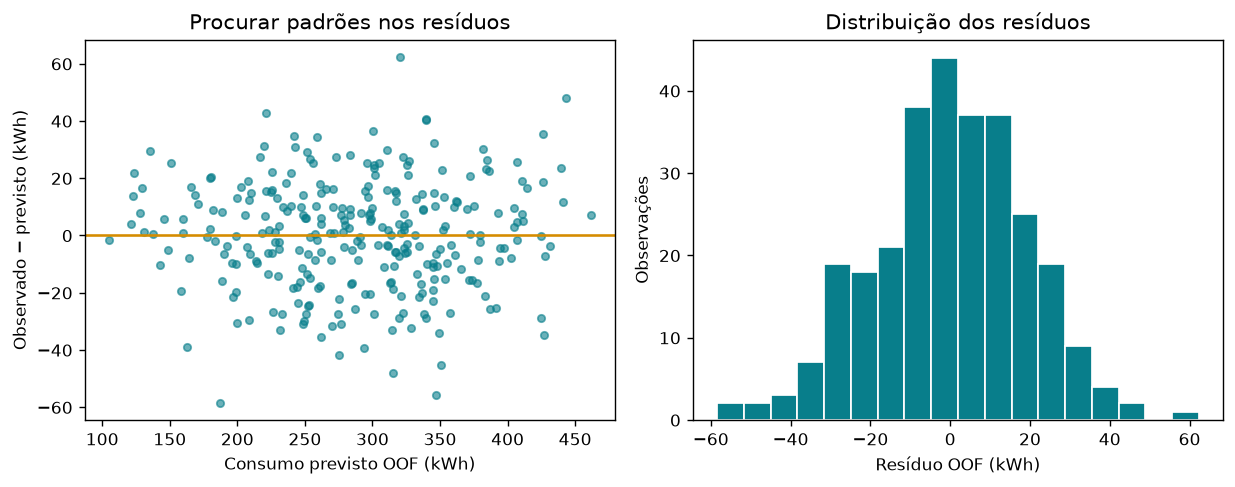

In [22]:
previsoes_oof = cross_val_predict(criar_pipeline(), X_dev, y_dev, cv=cv, n_jobs=1)
residuos_oof = y_dev.to_numpy() - previsoes_oof
print("MAE OOF:", mean_absolute_error(y_dev, previsoes_oof))
print("Média dos resíduos OOF:", residuos_oof.mean())
fig, eixos = plt.subplots(1, 2, figsize=(10,4))
eixos[0].scatter(previsoes_oof, residuos_oof, s=18, alpha=0.6, color="#087e8b")
eixos[0].axhline(0, color="#d58c00")
eixos[0].set(xlabel="Consumo previsto OOF (kWh)", ylabel="Observado − previsto (kWh)", title="Procurar padrões nos resíduos")
eixos[1].hist(residuos_oof, bins=18, color="#087e8b", edgecolor="white")
eixos[1].set(xlabel="Resíduo OOF (kWh)", ylabel="Observações", title="Distribuição dos resíduos")
fig.tight_layout(); mostrar_figura(fig)

**Interpretação:** Curvatura, assimetria ou variância crescente podem sugerir limitações do modelo ou dos dados; o gráfico não diagnostica automaticamente a causa. A métrica calculada sobre todas as previsões OOF não é, em geral, igual à média da métrica dos folds. Após escolher configurações com os mesmos folds, a avaliação independente continua a ser necessária.

### Exercício 7

Calcula os cinco MAE de validação da pipeline linear usando `cross_validate`, apresenta-os como erros positivos e calcula média e desvio entre folds. Explica a diferença entre os campos `test_score` da API e o teste reservado.

Tenta resolver antes de consultar a solução no final.

In [23]:
# Exercício 7 – escreve a tua resolução aqui.


## 8. Subajuste, sobreajuste e regressão polinomial
**Subajuste:** o modelo não representa a estrutura relevante e tem erros elevados mesmo no treino. **Sobreajuste:** adapta-se excessivamente aos detalhes do treino e generaliza pior.

Para mostrar estes comportamentos, criamos uma **experiência independente**, com uma relação não linear conhecida. Tem os seus próprios conjuntos de treino e validação. Não usa nem avalia o teste do cenário principal.

Uma regressão polinomial continua a ser linear nos coeficientes: as novas entradas são potências da variável. `PolynomialFeatures` constrói essas entradas. Com várias variáveis, pode criar também interações e crescer rapidamente em dimensão.

In [24]:
rng_curva = np.random.default_rng(88)
x_curva = np.sort(rng_curva.uniform(0, 1, 40))
def funcao_curva(x):
    return 2 + np.sin(2 * np.pi * x)
y_curva = funcao_curva(x_curva) + rng_curva.normal(0, 0.22, len(x_curva))
Xp_treino, Xp_val, yp_treino, yp_val = train_test_split(
    x_curva.reshape(-1,1), y_curva, test_size=0.35, random_state=13)

def criar_polinomio(grau, alpha=None):
    modelo = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return Pipeline([("polinomio", PolynomialFeatures(degree=grau, include_bias=False)),
                     ("escalar", StandardScaler()), ("modelo", modelo)])

modelos_curva = {}
comparacao_curva = []
for grau in [1, 4, 15]:
    estimador = criar_polinomio(grau).fit(Xp_treino, yp_treino)
    modelos_curva[grau] = estimador
    comparacao_curva.append({"grau": grau,
        "RMSE_treino": root_mean_squared_error(yp_treino, estimador.predict(Xp_treino)),
        "RMSE_validacao": root_mean_squared_error(yp_val, estimador.predict(Xp_val))})
tabela_curva = pd.DataFrame(comparacao_curva)
display(tabela_curva)

,grau,RMSE_treino,RMSE_validacao
0,1,0.541561,0.384788
1,4,0.185645,0.210772
2,15,0.141451,0.276928


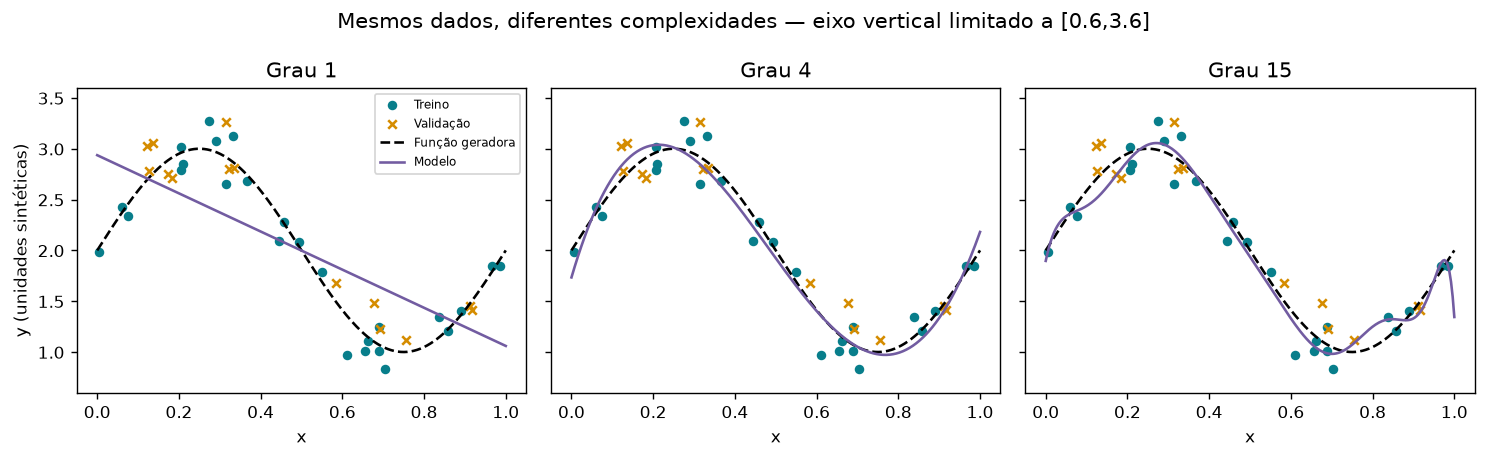

Previsões fora dos limites do gráfico podem estar ocultas; consulta os RMSE acima.


In [25]:
grelha = np.linspace(0, 1, 250).reshape(-1,1)
fig, eixos = plt.subplots(1, 3, figsize=(12,3.7), sharey=True)
for ax, grau in zip(eixos, [1,4,15]):
    ax.scatter(Xp_treino[:,0], yp_treino, s=20, color="#087e8b", label="Treino")
    ax.scatter(Xp_val[:,0], yp_val, s=24, marker="x", color="#d58c00", label="Validação")
    ax.plot(grelha[:,0], funcao_curva(grelha[:,0]), color="black", ls="--", label="Função geradora")
    ax.plot(grelha[:,0], modelos_curva[grau].predict(grelha), color="#725ca1", label="Modelo")
    ax.set(title=f"Grau {grau}", xlabel="x", ylim=(0.6,3.6))
eixos[0].set_ylabel("y (unidades sintéticas)")
eixos[0].legend(fontsize=7)
fig.suptitle("Mesmos dados, diferentes complexidades — eixo vertical limitado a [0.6,3.6]")
fig.tight_layout(); mostrar_figura(fig)
print("Previsões fora dos limites do gráfico podem estar ocultas; consulta os RMSE acima.")

Um grau mais alto não garante um modelo melhor. Compara treino e validação, não apenas a aparência da curva. O padrão mostrado depende da amostra; não há uma regra universal que escolha grau 4 ou rejeite grau 15 em qualquer problema.

`include_bias=False` evita acrescentar uma coluna de uns redundante quando o regressor já estima a interceção. `StandardScaler` fica dentro da pipeline para respeitar os folds quando usarmos validação cruzada.

### Exercício 8

Na experiência independente, ajusta grau 2 e apresenta RMSE de treino e validação. Compara com os graus já apresentados. Não alteres o conjunto de teste principal.

Tenta resolver antes de consultar a solução no final.

In [26]:
# Exercício 8 – escreve a tua resolução aqui.


## 9. Regularização: restringir coeficientes
Ridge acrescenta uma penalização quadrática à dimensão dos coeficientes:

$$\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_2^2.$$

Lasso acrescenta uma penalização baseada na soma dos módulos. Na implementação de Lasso, a escala do termo de erro inclui $1/(2n)$; por isso **não compares o mesmo valor de `alpha` entre Ridge e Lasso como se significasse a mesma intensidade**.

| Modelo | Efeito típico | Cuidado |
|---|---|---|
| Regressão linear | Minimiza o erro de ajuste sem penalização | Pode ficar instável com variáveis redundantes |
| Ridge | Encolhe coeficientes, habitualmente sem os tornar exatamente zero | Escalar entradas e escolher alpha no desenvolvimento |
| Lasso | Pode tornar alguns coeficientes exatamente zero | Seleção pode ser instável com variáveis correlacionadas |

Regularizar não elimina a necessidade de escolher variáveis, verificar dados e avaliar generalização. Com entradas em unidades diferentes, a escala afeta a penalização.

### 9.1 Regularizar a curva de grau elevado

Mantemos o mesmo grau e variamos `alpha`. Os resultados pertencem apenas à experiência de treino/validação independente.

In [27]:
regularizacao_curva = []
for alpha in [0.001, 0.1, 10., 1000.]:
    modelo_curva_ridge = criar_polinomio(15, alpha=alpha).fit(Xp_treino, yp_treino)
    regularizacao_curva.append({"alpha": alpha,
        "RMSE_treino": root_mean_squared_error(yp_treino, modelo_curva_ridge.predict(Xp_treino)),
        "RMSE_validacao": root_mean_squared_error(yp_val, modelo_curva_ridge.predict(Xp_val)),
        "norma_coef": np.linalg.norm(modelo_curva_ridge.named_steps["modelo"].coef_)})
display(pd.DataFrame(regularizacao_curva))

,alpha,RMSE_treino,RMSE_validacao,norma_coef
0,0.001,0.153099,0.240613,7.324763
1,0.100,0.224445,0.246816,2.979559
2,10.000,0.449488,0.367257,0.418204
3,1000.000,0.726567,0.758008,0.023441


**Interpretação:** Aumentar `alpha` tende a reduzir a dimensão dos coeficientes, mas pode conduzir a subajuste. A norma dos coeficientes só é comparável aqui porque a representação e o pré-processamento são os mesmos.

### 9.2 Introdução ao Lasso

Neste módulo, Lasso é uma apresentação conceptual e uma demonstração de ajuste. A seleção final principal ficará limitada às famílias linear e Ridge, definidas previamente.

In [28]:
lasso_demo = criar_pipeline(Lasso(alpha=1.0, max_iter=10000)).fit(X_dev, y_dev)
display(pd.DataFrame({"variavel": FEATURES,
                      "coef_lasso_padronizado": lasso_demo.named_steps["modelo"].coef_}))
print("Coeficientes exatamente zero:", np.count_nonzero(lasso_demo.named_steps["modelo"].coef_ == 0))
print("A demonstração não garante que alpha=1 seja adequado.")

,variavel,coef_lasso_padronizado
0,area_m2,61.374504
1,ocupantes,25.031671
2,temperatura_C,-34.029458


Coeficientes exatamente zero: 0
A demonstração não garante que alpha=1 seja adequado.


### Exercício 9

Compara Ridge com `alpha=0.1` e `alpha=100` por validação cruzada no desenvolvimento, usando a pipeline completa e os mesmos folds. Reporta os RMSE médios e não consultes o teste.

Tenta resolver antes de consultar a solução no final.

In [29]:
# Exercício 9 – escreve a tua resolução aqui.


## 10. Escolher uma configuração sem reutilizar o teste
Vamos selecionar entre **regressão linear múltipla** e **Ridge com quatro valores de alpha**, usando o menor RMSE médio na validação cruzada. É uma pesquisa pequena e explícita.

`GridSearchCV(refit=True)` escolhe a configuração pela validação cruzada e reajusta-a no desenvolvimento inteiro. As estatísticas dos transformadores são aprendidas dentro de cada treino de fold, pois a pesquisa recebe a pipeline completa.

O melhor resultado dos folds foi usado na escolha e pode ser otimista. O teste reservado dá uma avaliação independente do procedimento escolhido. Se fosse necessário comparar muitos procedimentos sem um teste independente, estudaríamos validação cruzada aninhada num módulo posterior.

In [30]:
pesquisa = GridSearchCV(
    estimator=criar_pipeline(),
    param_grid=[
        {"modelo": [LinearRegression()]},
        {"modelo": [Ridge()], "modelo__alpha": [0.01, 0.1, 10., 100.]}
    ],
    scoring="neg_root_mean_squared_error", cv=cv, refit=True,
    return_train_score=True, n_jobs=1, error_score="raise"
)
pesquisa.fit(X_dev, y_dev)
resultados_pesquisa = pd.DataFrame(pesquisa.cv_results_)
resumo_pesquisa = pd.DataFrame({
    "configuracao": resultados_pesquisa["params"].map(str),
    "RMSE_cv_media": -resultados_pesquisa["mean_test_score"],
    "desvio_folds": resultados_pesquisa["std_test_score"],
    "RMSE_ajuste_medio": -resultados_pesquisa["mean_train_score"]
}).sort_values("RMSE_cv_media")
display(resumo_pesquisa)
print("Configuração selecionada:", pesquisa.best_params_)
print("RMSE CV da configuração selecionada:", -pesquisa.best_score_)

,configuracao,RMSE_cv_media,desvio_folds,RMSE_ajuste_medio
0,{'modelo': LinearRegression()},18.911784,2.049743,18.744966
1,"{'modelo': Ridge(), 'modelo__alpha': 0.01}",18.911801,2.049601,18.744967
2,"{'modelo': Ridge(), 'modelo__alpha': 0.1}",18.911980,2.048329,18.744997
3,"{'modelo': Ridge(), 'modelo__alpha': 10.0}",19.206058,1.946375,19.025734
4,"{'modelo': Ridge(), 'modelo__alpha': 100.0}",30.067128,2.740029,29.906800


Configuração selecionada: {'modelo': LinearRegression()}
RMSE CV da configuração selecionada: 18.91178384670021


### 10.1 Verificar o ajuste final e aplicar uma regra de seleção

A referência também pode ganhar. A regra definida aqui escolhe a referência se o seu RMSE CV for inferior ao da pesquisa; caso contrário, usa a configuração da pesquisa. O teste não participa nesta decisão.

In [31]:
rmse_base_cv = float(tabela_cv.loc["referencia_media", "RMSE_cv_media"])
rmse_escolhido_cv = float(-pesquisa.best_score_)
if rmse_base_cv < rmse_escolhido_cv:
    modelo_final = DummyRegressor(strategy="mean").fit(X_dev, y_dev)
    nome_final = "referencia_media"
else:
    modelo_final = pesquisa.best_estimator_
    nome_final = type(modelo_final.named_steps["modelo"]).__name__
print("Modelo final definido antes de abrir o teste:", nome_final)
if isinstance(modelo_final, Pipeline):
    np.testing.assert_allclose(modelo_final.named_steps["imputar"].statistics_, X_dev.median().to_numpy())
    assert modelo_final.n_features_in_ == len(FEATURES)

Modelo final definido antes de abrir o teste: LinearRegression


### 10.2 Avaliação final no teste reservado
A partir desta célula, abrimos o teste para reportar o desempenho final do modelo escolhido e da referência. Não mudamos os parâmetros nem voltamos a selecionar com base nestes resultados.

Examinar erros pode gerar ideias para um projeto futuro, mas, depois de usar o teste para orientar novas decisões, ele deixa de ser uma avaliação independente dessas decisões.

,MAE_kwh,MSE_kwh2,RMSE_kwh,R2
referencia_media,67.532443,6536.365062,80.847789,-0.000786
modelo_selecionado,15.837640,426.208003,20.644806,0.934743


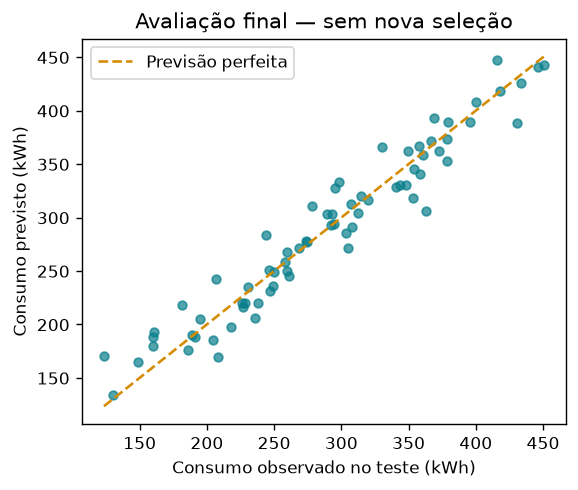

In [32]:
previsoes_teste = modelo_final.predict(X_teste)
referencia_final = DummyRegressor(strategy="mean").fit(X_dev, y_dev)
previsoes_base_teste = referencia_final.predict(X_teste)
metricas_teste = pd.DataFrame({
    "referencia_media": avaliar_regressao(y_teste, previsoes_base_teste),
    "modelo_selecionado": avaliar_regressao(y_teste, previsoes_teste)
}).T
display(metricas_teste)
assert len(previsoes_teste) == len(y_teste) and np.isfinite(previsoes_teste).all()
fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(y_teste, previsoes_teste, color="#087e8b", s=25, alpha=0.7)
limites = [min(y_teste.min(), previsoes_teste.min()), max(y_teste.max(), previsoes_teste.max())]
ax.plot(limites, limites, ls="--", color="#d58c00", label="Previsão perfeita")
ax.set(xlabel="Consumo observado no teste (kWh)", ylabel="Consumo previsto (kWh)", title="Avaliação final — sem nova seleção")
ax.legend(); mostrar_figura(fig)

Uma diferença entre o RMSE CV e o RMSE de teste é normal: usam observações distintas. Não escolhemos outra semente para aproximar os valores. A distribuição sintética foi construída com uma estrutura linear, pelo que este desempenho não demonstra utilidade numa operação energética real.

### Exercício 10

Sem reajustar nem comparar modelos no teste, calcula o erro absoluto médio apenas para as observações de teste acima de 120 m² e reporta o número de casos. Explica por que uma métrica de um subgrupo pequeno pode ser instável. Este exercício é descritivo e não orienta nova seleção.

Tenta resolver antes de consultar a solução no final.

In [33]:
# Exercício 10 – escreve a tua resolução aqui.


## 11. Miniprojeto de entrega: prever cenários novos e documentar
A pipeline final já está definida. Vamos prever três cenários fictícios, apresentar unidades e guardar a avaliação e as decisões. O projeto não disponibiliza um modelo para uso operacional; produz um relatório de aprendizagem reproduzível.

In [34]:
novos_cenarios = pd.DataFrame({
    "area_m2": [60., 110., 150.],
    "ocupantes": [1, 3, 4],
    "temperatura_C": [12., 18., np.nan]
})
assert novos_cenarios.columns.tolist() == FEATURES
novos_cenarios["consumo_previsto_kwh"] = modelo_final.predict(novos_cenarios[FEATURES])
display(novos_cenarios)
print("A ausência no terceiro cenário usa a imputação aprendida, não uma temperatura observada.")
print("As previsões são pontuais; não são intervalos de confiança nem garantias de consumo.")

,area_m2,ocupantes,temperatura_C,consumo_previsto_kwh
0,60.0,1,12.0,194.681380
1,110.0,3,18.0,270.423581
2,150.0,4,NaN,364.818692


A ausência no terceiro cenário usa a imputação aprendida, não uma temperatura observada.
As previsões são pontuais; não são intervalos de confiança nem garantias de consumo.


In [35]:
avaliacao_linhas = X_teste.copy()
avaliacao_linhas["id_habitacao"] = dados.loc[X_teste.index, "id_habitacao"]
avaliacao_linhas["observado_kwh"] = y_teste
avaliacao_linhas["previsto_kwh"] = previsoes_teste
avaliacao_linhas["residuo_kwh"] = y_teste - previsoes_teste
metricas_teste.to_csv(PASTA / "metricas_teste.csv", sep=";", decimal=",", encoding="utf-8-sig", index_label="modelo")
avaliacao_linhas.to_csv(PASTA / "previsoes_teste.csv", sep=";", decimal=",", encoding="utf-8-sig", index=False)
novos_cenarios.to_csv(PASTA / "novos_cenarios.csv", sep=";", decimal=",", encoding="utf-8-sig", index=False)
metadados = {
    "origem": "Dados sintéticos originais; semente 724",
    "versoes": VERSOES, "features": FEATURES, "alvo": "consumo_kwh",
    "linhas_dev": len(X_dev), "linhas_teste": len(X_teste),
    "split": "Aleatório 80/20; random_state=42; linhas independentes",
    "validacao": "5 folds; shuffle=True; random_state=19",
    "criterio": "Menor RMSE médio CV; referência pode ser selecionada",
    "modelo_final": nome_final,
    "melhores_parametros_pesquisa": {k: str(v) for k,v in pesquisa.best_params_.items()},
    "avaliacao_teste": metricas_teste.to_dict(orient="index"),
    "limitacoes": ["Dados sintéticos", "Sem avaliação externa real", "Temperatura assumida disponível", "Sem intervalos de previsão"]
}
(PASTA / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
print("Resultados guardados em:", PASTA)
# Verificar a associação entre IDs e previsões exportadas.
lido = pd.read_csv(PASTA / "previsoes_teste.csv", sep=";", decimal=",")
assert lido["id_habitacao"].tolist() == avaliacao_linhas["id_habitacao"].tolist()
np.testing.assert_allclose(lido["previsto_kwh"].to_numpy(), previsoes_teste)

Resultados guardados em: /content/sklearn01_lab


### 11.1 Como adaptar a um projeto teu
1. Define o alvo, as unidades e o momento da previsão.
2. Identifica variáveis realmente disponíveis nesse momento; exclui identificadores e informação futura sem justificação.
3. Escolhe uma separação compatível com o problema: aleatória, temporal ou por grupos.
4. Reserva o teste e define a métrica principal antes de comparar modelos.
5. Compara uma referência, um modelo simples e uma alternativa justificada.
6. Coloca todas as transformações aprendidas dentro da pipeline.
7. Escolhe configurações usando apenas desenvolvimento/validação cruzada.
8. Faz uma avaliação final, documenta limitações e guarda resultados com unidades.

**Autoavaliação:** atribui 0–2 pontos a cada item: ausente; parcial; executado e explicado. Total: 16 pontos.

A introdução a categorias, `ColumnTransformer`, classificação e modelos de conjunto ficará para os módulos seguintes. Não é necessário acrescentar esses temas para completar este percurso de regressão.

### Exercício 11

Escreve um pequeno relatório: objetivo; unidade de observação; momento de disponibilidade das entradas; separação; métrica principal; resultado versus referência; duas limitações. Usa os resultados existentes, sem fazer nova seleção.

Tenta resolver antes de consultar a solução no final.

In [36]:
# Exercício 11 – escreve a tua resolução aqui.


### Exercício 12

Faz um teste de consistência: confirma que o teste não partilha índices com o desenvolvimento, que o alvo não está nas entradas, que a previsão de uma linha tem forma `(1,)` e que a pipeline não altera o DataFrame recebido.

Tenta resolver antes de consultar a solução no final.

In [37]:
# Exercício 12 – escreve a tua resolução aqui.


## 12. Soluções comentadas
As soluções podem ser executadas sem preencher as tentativas. As que ajustam modelos usam apenas desenvolvimento ou a experiência polinomial independente; não alteram a seleção final.

### Exercícios 1–2 – API e forma das entradas

In [38]:
# 1 – fit_intercept é uma configuração anterior ao ajuste; coef_ é aprendido.
ex1_modelo = LinearRegression(fit_intercept=False)
assert ex1_modelo.get_params()["fit_intercept"] is False
print("Modelo criado, ainda sem coeficientes aprendidos.")

# 2 – Duas observações e uma variável: (2,1).
ex2_X = np.array([[2.], [11.]])
ex2_prev = reta.predict(ex2_X)
print("Forma:", ex2_X.shape, "| previsões:", ex2_prev)
assert ex2_X.shape == (2,1) and ex2_prev.shape == (2,)
print("2 km está dentro do intervalo observado; 11 km é extrapolação.")

Modelo criado, ainda sem coeficientes aprendidos.
Forma: (2, 1) | previsões: [ 7.79715302 26.37366548]
2 km está dentro do intervalo observado; 11 km é extrapolação.


### Exercícios 3–4 – Separação e métricas

In [39]:
# 3 – Dados independentes, sem alterar a partição principal.
ex3_rng = np.random.default_rng(5)
ex3_X = pd.DataFrame(ex3_rng.normal(size=(100,2)), columns=["a","b"])
ex3_y = pd.Series(2*ex3_X["a"] - ex3_X["b"] + ex3_rng.normal(size=100))
ex3_Xtr, ex3_Xte, ex3_ytr, ex3_yte = train_test_split(ex3_X, ex3_y, test_size=0.25, random_state=7)
print("Formas:", ex3_Xtr.shape, ex3_Xte.shape)
assert ex3_Xtr.shape == (75,2) and ex3_Xte.shape == (25,2)
assert set(ex3_Xtr.index).isdisjoint(ex3_Xte.index)
ex3_repetida = train_test_split(ex3_X, ex3_y, test_size=0.25, random_state=7)
pd.testing.assert_frame_equal(ex3_Xtr, ex3_repetida[0])

# 4 – Erros absolutos 1,2,1; quadrados 1,4,1.
ex4_real = np.array([5.,10.,15.]); ex4_prev = np.array([4.,12.,14.])
print("MAE:", mean_absolute_error(ex4_real, ex4_prev))
print("MSE:", mean_squared_error(ex4_real, ex4_prev))
print("RMSE:", root_mean_squared_error(ex4_real, ex4_prev))
assert np.isclose(mean_absolute_error(ex4_real, ex4_prev), 4/3)
assert np.isclose(mean_squared_error(ex4_real, ex4_prev), 2)
# Se o alvo for kWh, MAE e RMSE têm unidades kWh; MSE tem kWh².

Formas: (75, 2) (25, 2)
MAE: 1.3333333333333333
MSE: 2.0
RMSE: 1.4142135623730951


### Exercícios 5–6 – Pipeline e coeficientes

In [40]:
# 5 – Média aprendida apenas no desenvolvimento.
ex5_pipe = Pipeline([("imputar", SimpleImputer(strategy="mean")),
                     ("escalar", StandardScaler()), ("modelo", LinearRegression())])
ex5_pipe.fit(X_dev, y_dev)
ex5_transformado = ex5_pipe[:-1].transform(X_dev)
assert np.isfinite(ex5_transformado).all()
np.testing.assert_allclose(ex5_pipe.named_steps["imputar"].statistics_, X_dev.mean().to_numpy())
print("Preparação sem valores não finitos.")

# 6 – Corrigir escala e interceção antes de aplicar entradas não padronizadas.
ex6_entrada = X_dev.iloc[:1]
ex6_imputado = pipeline_linear.named_steps["imputar"].transform(ex6_entrada)
ex6_manual = ex6_imputado @ coef_original + intercecao_original
ex6_pipeline = pipeline_linear.predict(ex6_entrada)
np.testing.assert_allclose(ex6_manual, ex6_pipeline, atol=1e-10)
print("Manual:", ex6_manual, "| pipeline:", ex6_pipeline)
# Um coeficiente padronizado multiplica desvios em unidades de desvio padrão, não m² ou °C.

Preparação sem valores não finitos.
Manual: [213.32851015] | pipeline: [213.32851015]


### Exercícios 7–9 – Validação e regularização

In [41]:
# 7 – A API muda o sinal para maximização do score; apresentamos MAE positivo.
ex7_cv = cross_validate(criar_pipeline(), X_dev, y_dev, cv=cv,
                        scoring="neg_mean_absolute_error", n_jobs=1, error_score="raise")
ex7_erros = -ex7_cv["test_score"]
print("MAE dos folds:", ex7_erros)
print("Média:", ex7_erros.mean(), "| desvio:", ex7_erros.std(ddof=1))
# test_score é o score nas validações internas; X_teste continua a ser uma partição distinta.

# 8 – Experiência independente; não reajusta o modelo principal.
ex8_modelo = criar_polinomio(2).fit(Xp_treino, yp_treino)
display(pd.Series({"RMSE_treino_grau2": root_mean_squared_error(yp_treino, ex8_modelo.predict(Xp_treino)),
                   "RMSE_validacao_grau2": root_mean_squared_error(yp_val, ex8_modelo.predict(Xp_val))}))

# 9 – Mesmos folds para tornar a comparação emparelhada.
ex9_linhas = []
for a in [0.1,100.]:
    ex9_cv = cross_validate(criar_pipeline(Ridge(alpha=a)), X_dev, y_dev, cv=cv,
                            scoring="neg_root_mean_squared_error", error_score="raise", n_jobs=1)
    ex9_linhas.append({"alpha": a, "RMSE_cv": -ex9_cv["test_score"].mean()})
display(pd.DataFrame(ex9_linhas))
print("Exercícios de desenvolvimento; não mudamos a configuração final com base no teste.")

MAE dos folds: [13.84861161 12.64563225 15.68465304 17.97923206 15.13135655]
Média: 15.057897103155387 | desvio: 2.013318798790914


RMSE_treino_grau2       0.541211
RMSE_validacao_grau2    0.382784
dtype: float64

,alpha,RMSE_cv
0,0.1,18.911980
1,100.0,30.067128


Exercícios de desenvolvimento; não mudamos a configuração final com base no teste.


### Exercícios 10–12 – Avaliação descritiva e consistência

In [42]:
# 10 – Subgrupo descritivo; manter os casos e o denominador explícitos.
ex10_mascara = X_teste["area_m2"].to_numpy() > 120
ex10_n = int(ex10_mascara.sum())
if ex10_n:
    ex10_mae = mean_absolute_error(y_teste.to_numpy()[ex10_mascara], previsoes_teste[ex10_mascara])
    print("Teste, área >120 m²:", ex10_n, "casos; MAE:", ex10_mae, "kWh")
else:
    print("Sem casos neste subgrupo.")
# Poucos casos tornam o resultado mais sensível às observações específicas.

# 11 – Relatório com resultados já obtidos; nenhuma nova seleção.
ex11_relatorio = f"""Objetivo: estimar consumo mensal de energia de habitações fictícias.
Unidade: uma habitação num cenário mensal; alvo em kWh.
Entradas: área, ocupantes e cenário de temperatura assumido disponível ao prever.
Separação: desenvolvimento 80%; teste 20%; linhas independentes.
Escolha: menor RMSE CV em cinco folds; referência comparada explicitamente.
Modelo final: {nome_final}.
RMSE teste do modelo: {metricas_teste.loc['modelo_selecionado','RMSE_kwh']:.2f} kWh.
RMSE teste da referência: {metricas_teste.loc['referencia_media','RMSE_kwh']:.2f} kWh.
Limitações: dados sintéticos com mecanismo linear; temperatura real pode não estar disponível
no momento da previsão; ausência de validação externa e de intervalos de previsão.
"""
print(ex11_relatorio)
(PASTA / "relatorio.md").write_text(ex11_relatorio, encoding="utf-8")

# 12 – Contratos essenciais de uma previsão.
assert set(X_dev.index).isdisjoint(X_teste.index)
assert "consumo_kwh" not in FEATURES
ex12_entrada = X_dev.iloc[:1].copy(deep=True)
ex12_copia = ex12_entrada.copy(deep=True)
ex12_previsao = modelo_final.predict(ex12_entrada)
assert ex12_previsao.shape == (1,)
pd.testing.assert_frame_equal(ex12_entrada, ex12_copia)
print("Separação, ausência do alvo, forma e preservação da entrada verificadas.")

Teste, área >120 m²: 30 casos; MAE: 16.04890078246228 kWh
Objetivo: estimar consumo mensal de energia de habitações fictícias.
Unidade: uma habitação num cenário mensal; alvo em kWh.
Entradas: área, ocupantes e cenário de temperatura assumido disponível ao prever.
Separação: desenvolvimento 80%; teste 20%; linhas independentes.
Escolha: menor RMSE CV em cinco folds; referência comparada explicitamente.
Modelo final: LinearRegression.
RMSE teste do modelo: 20.64 kWh.
RMSE teste da referência: 80.85 kWh.
Limitações: dados sintéticos com mecanismo linear; temperatura real pode não estar disponível
no momento da previsão; ausência de validação externa e de intervalos de previsão.

Separação, ausência do alvo, forma e preservação da entrada verificadas.


## 13. Consulta rápida
| Intenção | API |
|---|---|
| Separar dados independentes | `train_test_split` |
| Prever um valor constante aprendido | `DummyRegressor` |
| Ajustar regressão linear | `LinearRegression` |
| Imputar | `SimpleImputer` |
| Padronizar | `StandardScaler` |
| Compor preparação e modelo | `Pipeline` |
| Criar potências e interações | `PolynomialFeatures` |
| Regularização L2 / L1 | `Ridge` / `Lasso` |
| Avaliar vários folds e métricas | `cross_validate` |
| Obter previsões fora do fold de treino | `cross_val_predict` |
| Pesquisar configurações | `GridSearchCV` |
| Clonar a configuração sem estado aprendido | `clone` |
| MAE / MSE / RMSE / R² | Funções de `sklearn.metrics` |

### Erros frequentes e como os reconhecer
| Sintoma / prática | Causa ou problema | Resposta |
|---|---|---|
| “Expected 2D array” | Entrada 1D em vez de matriz | Rever observações e variáveis; uma coluna pode ser `df[[coluna]]` |
| `NotFittedError` | Previsão antes de ajuste | Ajustar no treino antes de prever |
| Falha com NaN | O estimador não aceita essas ausências | Imputação justificada dentro da pipeline |
| Erro de ajuste muito baixo, validação pior | Possível sobreajuste ou mudança de distribuição | Verificar complexidade, dados e separação |
| Score negativo de MAE/RMSE | Convenção neg_* da API | Inverter o sinal ao apresentar o erro |
| Preparar o conjunto inteiro antes da CV | Estatísticas da validação entram no treino | Usar a pipeline completa na CV |
| Escolher após ver o teste repetidamente | O teste passou a orientar a seleção | Reservar uma avaliação independente futura |
| Coeficientes tratados como efeitos causais | Associação confundida com intervenção | Limitar a interpretação ao modelo e aos dados |
| `ConvergenceWarning` no Lasso | Otimização não convergiu adequadamente | Verificar escalas, dados, tolerâncias e iterações; não esconder o aviso |

### O que fica para os próximos módulos
**Classificação e seleção de modelos:** classificação, probabilidades, limiares, métricas de classificação, categorias e ColumnTransformer.

**Aplicações e consolidação:** modelos de conjunto, aprendizagem não supervisionada, PCA, interpretação, separações por grupos/tempo e disponibilização de modelos.

Não gravamos um objeto serializado neste módulo: o objetivo é compreender o processo e produzir uma entrega auditável de resultados.

### Referências oficiais
- [Scikit-learn – primeiros passos](https://scikit-learn.org/stable/getting_started.html)
- [Modelos lineares](https://scikit-learn.org/stable/modules/linear_model.html)
- [Avaliação de modelos](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Pipelines](https://scikit-learn.org/stable/modules/compose.html)
- [Erros frequentes e fuga de informação](https://scikit-learn.org/stable/common_pitfalls.html)
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

A documentação complementa o tutorial; não é necessário aceder-lhe para executar os exemplos.